# d.4.4 Micrograd — backprop и простая нейросеть руками

Видео: [Karpathy — building micrograd](https://www.youtube.com/watch?v=VMj-3S1tku0) · репо: [karpathy/micrograd](https://github.com/karpathy/micrograd) · краткий итог и самопроверка: [`d.4.4`](d.4.4%20Разбор%20backword%20и%20простой%20нейросети.md)

Запускать сверху вниз (`Shift+Enter`). Части 7–8 импортируют пакет `micrograd`: он установлен из папки `учеба мл/micrograd`, без неё эти части не запустятся.

| часть | что делаем | конспект |
| --- | --- | --- |
| 1–2 | производная численно, частные производные | [`d.0` §2–3](../../d.0%20Градиент%20и%20правило%20цепочки.md) |
| 3 | `Value` помнит историю вычислений (граф) | [`d.0` §8](../../d.0%20Градиент%20и%20правило%20цепочки.md) |
| 4 | backprop руками по графу | [`d.0` §8–9](../../d.0%20Градиент%20и%20правило%20цепочки.md) |
| 5 | шаг `w -= lr * grad` | [`d.0` §5](../../d.0%20Градиент%20и%20правило%20цепочки.md), [`d.4.2`](../d.4.2%20Градиентная%20оптимизация.md) |
| 6 | автоматический `backward()` | [`d.4.1` §11](../d.4.1%20Полносвязные%20нейронные%20сети.md) |
| 7 | нейрон, MLP, цикл обучения | [`d.4.1` §5–7](../d.4.1%20Полносвязные%20нейронные%20сети.md) |
| 8 | полумесяцы: hinge + L2 + lr decay | [`d.2.1.11`](../../d.2%20Линейные%20модели%20метрические%20методы/d.2.1%20Линейные%20модели/d.2.1.11%20Упрощенное%20пояснение%20линейной%20классификации%20с%20примером.md), [`d.4.3`](../d.4.3%20Регуляризация%20в%20Deep%20Learning/d.4.3%20Регуляризация%20в%20Deep%20Learning.md) |

## Часть 1–2. Производная на пальцах (~0:00–19:00)

Связь с конспектом: [`d.0` §2](../../d.0%20Градиент%20и%20правило%20цепочки.md) — производная = скорость изменения; численно это `(f(x+h) − f(x)) / h`.

In [62]:
# Подключаем библиотеки (один раз в начале ноутбука)
import math                      # математика (пока почти не нужна)
import numpy as np               # массивы чисел — удобно для графика
import matplotlib.pyplot as plt  # рисование графиков

# следующая строка — magic Jupyter: график рисуется прямо в ноутбуке
# (комментарий нельзя писать в конце этой строки — Jupyter ругается)
%matplotlib inline

### Функция одного аргумента

Как идея функции в [`d.0` §1](../../d.0%20Градиент%20и%20правило%20цепочки.md).

In [63]:
# → d.0 §1: функция = вход → выход
# Обычная функция одного аргумента: на вход x, на выход число
# Это «чёрный ящик», у которого потом будем искать наклон (производную)
def f(x):
    return 3 * x**2 - 4 * x + 5  # 3*(x в квадрате) минус 4*x плюс 5


# Проверка руками: 3*9 - 4*3 + 5 = 27 - 12 + 5 = 20
f(3.0)  # в Out должно быть 20.0

20.0

### График — смотри глазами

Парабола. В точке `x=2` наклон должен быть крутой вверх (производная ≈ 8).

Text(0.5, 1.0, 'f(x) = 3x² − 4x + 5')

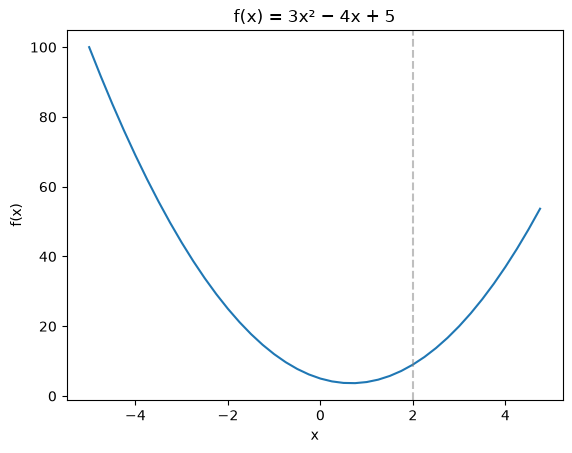

In [64]:
# → «Расчёт производной» (чашка): по графику видно, где f растёт, где падает
# Много точек по оси x: от -5 до 5 с шагом 0.25
xs = np.arange(-5, 5, 0.25)

# Для каждой точки считаем f(x) — получаем массив ys
ys = f(xs)

# Рисуем кривую: по горизонтали xs, по вертикали ys
plt.plot(xs, ys)

# Серая пунктирная линия в x=2 — там ниже будем считать наклон
plt.axvline(2.0, color="gray", linestyle="--", alpha=0.5)

plt.xlabel("x")  # подпись оси
plt.ylabel("f(x)")
plt.title("f(x) = 3x² − 4x + 5")  # заголовок графика

### Численная производная

Формула из [`d.0` §2](../../d.0%20Градиент%20и%20правило%20цепочки.md):

$$
\frac{f(x+h) - f(x)}{h}
$$

Аналитически `f'(x) = 6x − 4`. При `x = 2` → скорость ≈ `8` (не высота `f(2)=9`).

**Та же суть, другие буквы.** В [`d.0` §2](../../d.0%20Градиент%20и%20правило%20цепочки.md) берут `f(w) = w²` и при `w = 3` получают скорость ≈ `6`. Здесь — `f(x)` и `x = 2` → ≈ `8`. Буквы `x` / `w` разные (в ML крутят веса), вопрос один: «чуть сдвинул вход → насколько быстро меняется выход».

In [65]:
# Численная производная = «чуть сдвинули x → насколько выросла f»
# то же, что в d.0 §2: (f(x+h) - f(x)) / h
#
# В d.0 §2: f(w)=w², w=3 → скорость ≈ 6
# Здесь:     f(x)=3x²-4x+5, x=2 → скорость ≈ 8
# Буквы разные (x vs w), суть одна — скорость изменения

h = 0.0001  # крошечный шаг
x = 2.0  # точка, в которой смотрим наклон

# ≈ наклон в точке 2; аналитически f'=6x-4 → 8
# это скорость, не высота f(2)=9
(f(x + h) - f(x)) / h

8.000300000023941

### Несколько входов — частные производные

Связь: [`d.0` §3](../../d.0%20Градиент%20и%20правило%20цепочки.md) — `dL/dw` = «чуть изменить w → как быстро изменится лосс». Здесь то же: `dd/da` = «чуть изменить a → как быстро изменится d».

Число −3 значит: сдвиг `a` на **1** → `d` примерно на **−3**; сдвиг на `h` → примерно на **−3·h**.

Здесь `d = a*b + c`. Двигаем по очереди только один вход.

In [66]:
# Теперь выход зависит от НЕСКОЛЬКИХ входов (как лосс от нескольких весов в d.0)
# d = a*b + c

a = 2.0
b = -3.0
c = 10.0

# Исходное значение d (ничего ещё не двигали)
d0 = a * b + c
print("d =", d0)  # 2*(-3) + 10 = 4

h = 0.0001  # тот же крошечный шаг

# --- частная производная по a: двигаем ТОЛЬКО a, b и c как были ---
# Ожидаем ≈ b = -3
# Как читать dd/da ≈ -3 (то же, что dL/dw в d.0 §3):
#   сдвинул a на 1  → d изменится примерно на -3
#   сдвинул a на h  → d изменится примерно на -3*h
#   (при h=0.0001 это ≈ -0.0003, не «минус три целиком»)
d1 = (a + h) * b + c
print("dd/da ≈", (d1 - d0) / h)

# --- частная производная по b: двигаем ТОЛЬКО b ---
# Ожидаем ≈ a = 2  (сдвиг b на 1 → d ≈ +2; на h → ≈ +2*h)
d2 = a * (b + h) + c
print("dd/db ≈", (d2 - d0) / h)

# --- частная производная по c: двигаем ТОЛЬКО c ---
# Ожидаем ≈ 1  (сдвиг c на 1 → d ≈ +1; на h → ≈ +1*h)
d3 = a * b + (c + h)
print("dd/dc ≈", (d3 - d0) / h)

# Итог: число = скорость на единицу сдвига входа
# В сети: d → лосс L, a/b/c → веса w (см. d.0 §3, §6)

d = 4.0
dd/da ≈ -3.000000000010772
dd/db ≈ 2.0000000000042206
dd/dc ≈ 0.9999999999976694


---

### Чеклист частей 1–2

- [ ] `f(3.0)` дал `20.0`
- [ ] увидел график параболы
- [ ] численная производная ≈ `8`
- [ ] `dd/da ≈ -3`, `dd/db ≈ 2`, `dd/dc ≈ 1`

## Часть 3. Класс `Value` — число, которое помнит граф (~19:00)

Обычный `float` хранит только число. Нам нужно ещё помнить **из каких узлов** и **какой операцией** оно получилось — иначе потом не из чего делать backward.

**Конспекты:**
- граф и цепочка — [`d.0` §8](../../d.0%20Градиент%20и%20правило%20цепочки.md)
- поле `grad` позже = производная выхода по этому узлу — [`d.0` §2–3](../../d.0%20Градиент%20и%20правило%20цепочки.md)

Пока **не** импортируем готовый `micrograd.engine` — пишем минимальный `Value` сами.

In [67]:
# Value = «умное» число для autograd (заготовка под micrograd)
# data  — само значение (как float)
# grad  — место под производную выхода по этому узлу (пока 0; заполним на backward)
# _prev — родители в графе: из каких Value получился этот узел (см. d.0 §8 — цепочка)
# _op   — какая операция создала узел: '+', '*' или '' у листьев


class Value:
    def __init__(self, data, _children=(), _op=""):
        self.data = data
        self.grad = 0
        self._prev = set(_children)
        self._op = _op

    def __repr__(self):
        # чтобы print(a) был читаемым
        return f"Value(data={self.data})"


# Листья графа — просто числа, без родителей
a = Value(2.0)
b = Value(-3.0)
print(a, b)  # Value(data=2.0) Value(data=-3.0)

Value(data=2.0) Value(data=-3.0)


### `__add__` и `__mul__` — строим граф при вычислении

`a + b` в Python вызывает `a.__add__(b)`. Мы создаём **новый** `Value` с суммой и запоминаем родителей `(a, b)` и операцию `'+'`.

Это forward «по кирпичикам» — как в [`d.0` §8](../../d.0%20Градиент%20и%20правило%20цепочки.md), пока без производных.

In [68]:
# Переопределяем класс целиком (в ноутбуке так удобнее на каждом шаге видео)
class Value:
    def __init__(self, data, _children=(), _op=""):
        self.data = data
        self.grad = 0  # пока не считаем; см. d.0 §2 — сюда потом ляжет скорость
        self._prev = set(_children)  # рёбра графа «назад» к родителям
        self._op = _op

    def __repr__(self):
        return f"Value(data={self.data})"

    def __add__(self, other):
        # a + b → новый узел: data = сумма, родители = (self, other), op = '+'
        out = Value(self.data + other.data, (self, other), "+")
        return out

    def __mul__(self, other):
        # a * b → новый узел с произведением
        out = Value(self.data * other.data, (self, other), "*")
        return out


a = Value(2.0)
b = Value(-3.0)
c = Value(10.0)

# то же выражение, что в частях 1–2: d = a*b + c
e = a * b  # data=-6, родители a и b, op='*'
d = e + c  # data=4,  родители e и c, op='+'

print("d =", d)  # Value(data=4.0)
print("d._op =", d._op)  # '+'
print("d._prev =", d._prev)  # узлы e и c
print("e._op =", e._op)  # '*'
print("e._prev =", e._prev)  # узлы a и b

# Граф (снизу вверх):
# a=2 ──┐
#       ├─(*)→ e=-6 ──┐
# b=-3 ─┘             ├─(+)→ d=4
# c=10 ───────────────┘
# Позже пойдём наоборот (от d к a,b,c) и заполним .grad — это backprop

d = Value(data=4.0)
d._op = +
d._prev = {Value(data=-6.0), Value(data=10.0)}
e._op = *
e._prev = {Value(data=-3.0), Value(data=2.0)}


### Чеклист части 3

- [ ] `a`, `b` печатаются как `Value(data=...)`
- [ ] `d` = `Value(data=4.0)` (как `d0=4` в частях 1–2, только теперь это узел графа)
- [ ] у `d` операция `+`, у `e` — `*`
- [ ] `d._prev` и `e._prev` показывают родителей

## Часть 4. Ручной backprop (~32:00)

Граф уже есть. Теперь идём **от выхода назад** и руками заполняем `.grad` — «как выход зависит от этого узла».

**Конспект:** [`d.0` §8](../../d.0%20Градиент%20и%20правило%20цепочки.md) — правило цепочки: локальная скорость × скорость «сверху».

Сначала чуть расширим выражение (как в видео), чтобы был понятный финальный выход `L`:

In [69]:
# → d.0 §8: выражение = цепочка операций (граф)
# Тот же Value с + и * (перезапусти, если ядро перезапускал)
# Граф: L = (a*b + c) * f
#
# a=2 ──┐
#       ├─(*)→ e=-6 ──┐
# b=-3 ─┘             ├─(+)→ d=4 ──┐
# c=10 ───────────────┘            ├─(*)→ L=-8
# f=-2 ────────────────────────────┘

a = Value(2.0)
b = Value(-3.0)
c = Value(10.0)
f = Value(-2.0)

e = a * b  # -6
d = e + c  # 4
L = d * f  # -8

print("L =", L)  # Value(data=-8.0)

L = Value(data=-8.0)


### Заполняем `.grad` вручную — от `L` назад

`узёл.grad` = dL / d(этот узел) — скорость: чуть сдвинул узел → как изменится L (см. [`d.0` §2–3](../../d.0%20Градиент%20и%20правило%20цепочки.md)).

Правила локально:
- для `out = x + y`:  dx и dy получают тот же grad, что у out (производная суммы = 1)
- для `out = x * y`:  x получает `y * out.grad`, y получает `x * out.grad`

Плюс цепочка: умножаем на уже известный grad «сверху».

In [70]:
# → d.0 §8–9: grad узла = локальная производная × grad сверху
# 1) База: dL/dL = 1  (сдвинул L на 1 → L изменился на 1)
L.grad = 1.0

# 2) L = d * f  →  dL/dd = f,  dL/df = d
#    (локально) × (grad сверху = L.grad = 1)
d.grad = f.data * L.grad  # -2 * 1 = -2
f.grad = d.data * L.grad  #  4 * 1 =  4

# 3) d = e + c  →  dL/de = dL/dd * 1,  dL/dc = dL/dd * 1
e.grad = 1.0 * d.grad  # -2
c.grad = 1.0 * d.grad  # -2

# 4) e = a * b  →  dL/da = b * dL/de,  dL/db = a * dL/de
a.grad = b.data * e.grad  # -3 * -2 = 6
b.grad = a.data * e.grad  #  2 * -2 = -4

print("L.grad", L.grad)  # 1
print("d.grad", d.grad)  # -2
print("f.grad", f.grad)  # 4
print("e.grad", e.grad)  # -2
print("c.grad", c.grad)  # -2
print("a.grad", a.grad)  # 6   ← dL/da
print("b.grad", b.grad)  # -4  ← dL/db

# Проверка численно (как в части 1–2): чуть сдвинем a и посмотрим L
h = 0.0001
a2 = Value(2.0 + h)
e2 = a2 * b
d2 = e2 + c
L2 = d2 * f
print("численно dL/da ≈", (L2.data - L.data) / h)  # ≈ 6

L.grad 1.0
d.grad -2.0
f.grad 4.0
e.grad -2.0
c.grad -2.0
a.grad 6.0
b.grad -4.0
численно dL/da ≈ 6.000000000021544


### Что только что сделали

1. Forward: посчитали `L = -8` (история в `_prev`).
2. Backward руками: от `L` назад заполнили `.grad` у каждого узла.
3. `a.grad = 6` = dL/da — то же, что частная производная в части 1–2, только через цепочку по графу ([`d.0` §8–9](../../d.0%20Градиент%20и%20правило%20цепочки.md)).

Дальше в видео это автоматизируют (`_backward` у каждой операции). Пока важно: **backprop = цепочка по истории вычислений**.

### Чеклист

- [ ] `L.data == -8`
- [ ] `a.grad == 6`, `b.grad == -4`
- [ ] численная проверка `dL/da ≈ 6`

## Часть 5. Один шаг оптимизации (~51:00)

Градиенты есть → двигаем входы **против** градиента, чтобы уменьшить L (если хотим минимум).

**Конспекты:** [`d.0` §5, §10](../../d.0%20Градиент%20и%20правило%20цепочки.md) — шаг `w ← w − α·grad`; [`d.4.2` SGD](../../d.4%20Deep%20Learning/d.4.2%20Градиентная%20оптимизация.md).

In [71]:
# Нужны свежие grad с части 4. Если ядро перезапускал — сначала снова
# запусти ячейки с Value, графом L и ручным заполнением .grad

lr = 0.01  # α — learning rate (d.0 §5, d.4.2)

print("L до шага:", L.data)  # -8

# Шаг по листьям, которые «крутим» (как веса). Знак минус = против градиента
a.data += -lr * a.grad
b.data += -lr * b.grad
c.data += -lr * c.grad
f.data += -lr * f.grad

# Forward заново с новыми data (граф тот же по структуре, числа другие)
e = a * b
d = e + c
L = d * f
print("L после шага:", L.data)  # ≈ -8.73 — меньше, чем -8
# «меньше» для лосса хорошо; здесь L отрицательный — «меньше» = ещё левее по оси,
# но смысл как в d.0: шаг против grad двигает выход в нужную сторону для минимизации

L до шага: -8.0
L после шага: -8.726303999999999


## Часть 6. Автоматический `_backward` (~1:09)

Вручную расписывать каждый узел неудобно. Вшиваем правило прямо в `+` и `*`:
у каждого `out` есть функция `_backward()`, которая **проталкивает** `out.grad` родителям.

Потом `L.backward()` обойдёт граф в нужном порядке (с конца) и вызовет эти функции.

Это уже ядро **micrograd** / то, что в PyTorch делает autograd ([`d.4.1` §11](../../d.4%20Deep%20Learning/d.4.1%20Полносвязные%20нейронные%20сети.md)).

In [72]:
# → d.4.1 §11: backprop = цепочка по графу; в PyTorch это делает autograd
class Value:
    def __init__(self, data, _children=(), _op=""):
        self.data = data
        self.grad = 0.0
        self._prev = set(_children)
        self._op = _op
        # по умолчанию пустая функция (у листьев backward нечего делать)
        self._backward = lambda: None

    def __repr__(self):
        return f"Value(data={self.data}, grad={self.grad})"

    def __add__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        out = Value(self.data + other.data, (self, other), "+")

        def _backward():
            # out = self + other → dL/dself += out.grad, то же для other
            # += важно, если узел используется несколько раз (баг из видео ~1:22)
            self.grad += out.grad
            other.grad += out.grad

        out._backward = _backward
        return out

    def __mul__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        out = Value(self.data * other.data, (self, other), "*")

        def _backward():
            # out = self * other → self получает other.data * out.grad
            self.grad += other.data * out.grad
            other.grad += self.data * out.grad

        out._backward = _backward
        return out

    def backward(self):
        # топологическая сортировка: родители раньше детей → reversed = с конца
        # (нужно, чтобы out.grad уже был известен, когда зовём out._backward)
        topo = []
        visited = set()

        def build_topo(v):
            if v not in visited:
                visited.add(v)
                for child in v._prev:
                    build_topo(child)
                topo.append(v)

        build_topo(self)

        self.grad = 1.0  # dL/dL = 1
        for v in reversed(topo):
            v._backward()


# Тот же пример, но grad считает backward()
a = Value(2.0)
b = Value(-3.0)
c = Value(10.0)
f = Value(-2.0)
L = (a * b + c) * f

L.backward()

print("L", L)
print("a.grad", a.grad)  # 6
print("b.grad", b.grad)  # -4
print("c.grad", c.grad)  # -2
print("f.grad", f.grad)  # 4
# Сравни с ручным backprop из части 4 — те же числа

L Value(data=-8.0, grad=1.0)
a.grad 6.0
b.grad -4.0
c.grad -2.0
f.grad 4.0


### Чеклист частей 5–6

- [ ] после шага с `lr` новое `L` изменилось «в нужную сторону»
- [ ] `L.backward()` дал те же grad, что руками: `a=6`, `b=-4`, `c=-2`, `f=4`

**Смысл:** история (`_prev`) + локальные правила в `_backward` + обход с конца = automatic differentiation. Готовый файл `micrograd/engine.py` — развитие этой идеи (+ `relu`, `**` и т.д.).

## Часть 7. Нейрон и MLP (~1:43)

`Value` умеет forward + backward. Собираем из него сеть: **Neuron → Layer → MLP** — как в [`d.4.1` §5–7](../../d.4%20Deep%20Learning/d.4.1%20Полносвязные%20нейронные%20сети.md).

Здесь берём готовый модуль из репо (тот же код, что пишут в видео):

In [73]:
# Готовый engine из репо уже с relu, **, backward и т.д.
# (наша часть 6 — упрощённая версия того же)
from micrograd.engine import Value
from micrograd.nn import Neuron, Layer, MLP

# Один нейрон: nin=2 входа → z = w1*x1 + w2*x2 + b → ReLU(z)
# см. d.4.1 §5 — один нейрон = линейная комбинация + активация
n = Neuron(2)
x = [Value(1.0), Value(-2.0)]
y = n(x)  # forward одного нейрона

print("выход нейрона:", y)
print("число параметров (веса+bias):", len(n.parameters()))  # 2 + 1 = 3
print("параметры:", n.parameters())

выход нейрона: Value(data=0, grad=0)
число параметров (веса+bias): 3
параметры: [Value(data=-0.9842902124596047, grad=0), Value(data=0.8657982065184999, grad=0), Value(data=0, grad=0)]


### MLP — несколько слоёв

`MLP(nin, nouts)`: `nin` входов, `nouts` — список размеров слоёв.

Пример `MLP(3, [4, 4, 1])`:
- вход 3 числа
- скрытый слой 4 нейрона
- ещё скрытый 4
- выход 1 нейрон (без ReLU на последнем — так в `nn.py`)

Как конвейер в [`d.4.1` §7](../../d.4%20Deep%20Learning/d.4.1%20Полносвязные%20нейронные%20сети.md).

In [74]:
# → d.4.1 §7: слои подряд = MLP; у выходного слоя нет ReLU
model = MLP(3, [4, 4, 1])
print(model)
print("всего параметров:", len(model.parameters()))
# 1-й слой: 4 нейрона * (3 w + 1 b) = 16
# 2-й: 4 * (4+1) = 20
# 3-й: 1 * (4+1) = 5  → 16+20+5 = 41

xs = [Value(2.0), Value(3.0), Value(-1.0)]
y_hat = model(xs)  # forward всей сети → один Value
print("предсказание ŷ:", y_hat)

# backward по выходу (пока без «настоящего» лосса — просто d(ŷ)/d(w))
y_hat.backward()
print("grad первого веса:", model.parameters()[0].grad)
# Веса ещё НЕ обновляли — только посчитали grad (как часть 6)

MLP of [Layer of [ReLUNeuron(3), ReLUNeuron(3), ReLUNeuron(3), ReLUNeuron(3)], Layer of [ReLUNeuron(4), ReLUNeuron(4), ReLUNeuron(4), ReLUNeuron(4)], Layer of [LinearNeuron(4)]]
всего параметров: 41
предсказание ŷ: Value(data=0.0, grad=0)
grad первого веса: 0.0


### Мини-обучение на 4 примерах (~1:51)

Лосс = средний квадрат ошибки (MSE), как идея в [`d.0` §6](../../d.0%20Градиент%20и%20правило%20цепочки.md) / классике.

Цикл: forward → loss → `backward()` → шаг по всем `parameters()` → `zero_grad`.

**Важно:** метки здесь ±1, то есть это классификация. MSE взят для простоты, как в видео. Для классификации это плохой выбор: штрафует уверенно правильный ответ — см. [`d.2.1.11`, шаг 2](../../d.2%20Линейные%20модели%20метрические%20методы/d.2.1%20Линейные%20модели/d.2.1.11%20Упрощенное%20пояснение%20линейной%20классификации%20с%20примером.md). В части 8 уже стоит hinge.

In [75]:
# Крошечный датасет из видео (4 объекта, 3 признака, метка ±1)
xs = [
    [2.0, 3.0, -1.0],
    [3.0, -1.0, 0.5],
    [0.5, 1.0, 1.0],
    [1.0, 1.0, -1.0],
]
ys = [1.0, -1.0, -1.0, 1.0]  # желаемые ответы

model = MLP(3, [4, 4, 1])
lr = 0.1

for step in range(20):
    # --- forward: предсказания ---
    ypred = [model([Value(v) for v in x]) for x in xs]

    # --- лосс: средний (ŷ - y)^2 ---
    # MSE на метках ±1 — упрощение из видео; почему так не надо → d.2.1.11, шаг 2
    loss = sum((yout - ytrue) ** 2 for ytrue, yout in zip(ys, ypred))
    loss = loss * (1.0 / len(ys))  # усреднили; * чтобы остался Value

    # --- важно: обнулить grad перед backward (иначе += накопит мусор) ---
    model.zero_grad()

    # --- backward: градиенты по всем весам ---
    loss.backward()

    # --- шаг SGD по каждому параметру (часть 5) ---
    for p in model.parameters():
        p.data += -lr * p.grad

    if step % 5 == 0 or step == 19:
        print(f"step {step:2d}  loss={loss.data:.4f}")

print("предсказания в конце:", [yp.data for yp in ypred])
print("цели:               ", ys)
# loss должен падать; предсказания — ближе к ±1

step  0  loss=0.9750
step  5  loss=0.2069
step 10  loss=0.1298
step 15  loss=0.0487
step 19  loss=0.2363
предсказания в конце: [0.3523484266618069, -1.2927243560818906, -1.1747746978492246, 0.36009070915371655]
цели:                [1.0, -1.0, -1.0, 1.0]


### Чеклист части 7

- [ ] нейрон и MLP создаются, `parameters()` не пустой
- [ ] за 20 шагов `loss` в целом падает
- [ ] понимаешь цикл: forward → loss → `zero_grad` → `backward` → обновить веса

Это тот же каркас, что в [`d.4.1` §11](../../d.4%20Deep%20Learning/d.4.1%20Полносвязные%20нейронные%20сети.md) и [`d.4.2`](../../d.4%20Deep%20Learning/d.4.2%20Градиентная%20оптимизация.md). `demo.ipynb` — то же на moons с картинкой границы.

## Часть 8. Финал: классификация «полумесяцев» (`demo.ipynb`)

То же обучение, что в части 7, но на настоящей задаче: 100 точек двух классов на плоскости, сеть учится их разделять. Здесь всплывают темы из всех твоих конспектов:

| в коде | что это | конспект |
| --- | --- | --- |
| `make_moons` | датасет: 100 сэмплов, 2 признака | — |
| `MLP(2, [16, 16, 1])` | 2 скрытых слоя по 16 нейронов | [`d.4.1` §7](../../d.4%20Deep%20Learning/d.4.1%20Полносвязные%20нейронные%20сети.md) |
| `(1 - y·score).relu()` | hinge loss (как в SVM) | [`d.2.1`](../../d.2%20Линейные%20модели%20метрические%20методы/d.2.1%20Линейные%20модели/d.2.1%20Линейные%20модели.md) |
| `alpha * sum(p*p)` | L2 = weight decay | [`d.4.3` §2.1](../../d.4%20Deep%20Learning/d.4.3%20Регуляризация%20в%20Deep%20Learning/d.4.3%20Регуляризация%20в%20Deep%20Learning.md) |
| `accuracy` | метрика, не лосс | [`d.4.3` §3.2](../../d.4%20Deep%20Learning/d.4.3%20Регуляризация%20в%20Deep%20Learning/d.4.3%20Регуляризация%20в%20Deep%20Learning.md) |
| `learning_rate = 1.0 - 0.9*k/100` | lr decay: шаг уменьшается | [`d.4.2` §2.6](../../d.4%20Deep%20Learning/d.4.2%20Градиентная%20оптимизация.md) |

Text(0.5, 1.0, 'make_moons: 2 класса')

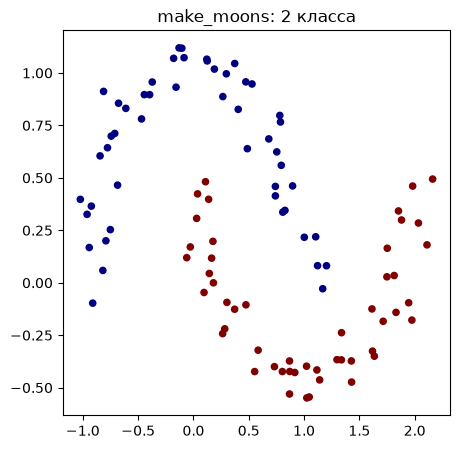

In [76]:
import random
from sklearn.datasets import make_moons
from micrograd.engine import Value
from micrograd.nn import MLP

# фиксируем случайность, чтобы результат повторялся
np.random.seed(1337)
random.seed(1337)

# 100 сэмплов (точек), у каждого 2 признака (координаты x1, x2)
X, y = make_moons(n_samples=100, noise=0.1)
y = y * 2 - 1  # метки 0/1 → -1/+1 (так удобнее для hinge loss)

# смотрим глазами: два класса — два полумесяца
plt.figure(figsize=(5, 5))
plt.scatter(X[:, 0], X[:, 1], c=y, s=20, cmap="jet")
plt.title("make_moons: 2 класса")

In [77]:
# Сеть: 2 входа → 16 → 16 → 1 выход (score).
# score > 0 → класс +1, score < 0 → класс -1
model = MLP(2, [16, 16, 1])
print("параметров:", len(model.parameters()))  # 337


def loss():
    inputs = [list(map(Value, xrow)) for xrow in X]

    # forward: score для каждой точки
    scores = list(map(model, inputs))

    # hinge loss = max(0, 1 - M), где M = y·score — отступ (d.2.1, раздел «Отступ»).
    # relu() здесь и есть max(0, ...). Штраф 0, только если класс угадан с запасом M ≥ 1
    losses = [(1 + -yi * scorei).relu() for yi, scorei in zip(y, scores)]
    data_loss = sum(losses) * (1.0 / len(losses))

    # L2-регуляризация = weight decay (d.4.3 §2.1): штраф за большие веса
    alpha = 1e-4
    reg_loss = alpha * sum(p * p for p in model.parameters())
    total_loss = data_loss + reg_loss

    # accuracy — метрика (доля угаданных знаков), не лосс (d.4.3 §3.2)
    accuracy = [(yi > 0) == (scorei.data > 0) for yi, scorei in zip(y, scores)]
    return total_loss, sum(accuracy) / len(accuracy)


total_loss, acc = loss()
print("до обучения: loss", round(total_loss.data, 4), "accuracy", acc)

параметров: 337
до обучения: loss 0.8958 accuracy 0.5


In [78]:
# Цикл обучения — тот же, что в части 7. Займёт около минуты:
# micrograd считает каждое число отдельным Value, это медленно.
for k in range(100):
    # forward + loss
    total_loss, acc = loss()

    # backward: обнулить старые grad, посчитать новые
    model.zero_grad()
    total_loss.backward()

    # шаг SGD. lr уменьшается с 1.0 до 0.1 за 100 шагов —
    # это lr decay из d.4.2 §2.6: сначала большие шаги, к концу аккуратные
    learning_rate = 1.0 - 0.9 * k / 100
    for p in model.parameters():
        p.data -= learning_rate * p.grad

    if k % 10 == 0 or k == 99:
        print(f"step {k:3d}  loss {total_loss.data:.4f}  accuracy {acc * 100:.0f}%")

step   0  loss 0.8958  accuracy 50%
step  10  loss 0.2451  accuracy 91%
step  20  loss 0.1898  accuracy 91%
step  30  loss 0.1173  accuracy 95%
step  40  loss 0.0602  accuracy 100%
step  50  loss 0.0988  accuracy 96%
step  60  loss 0.0326  accuracy 99%
step  70  loss 0.0142  accuracy 100%
step  80  loss 0.0123  accuracy 100%
step  90  loss 0.0110  accuracy 100%
step  99  loss 0.0110  accuracy 100%


Text(0.5, 1.0, 'Граница решения после обучения')

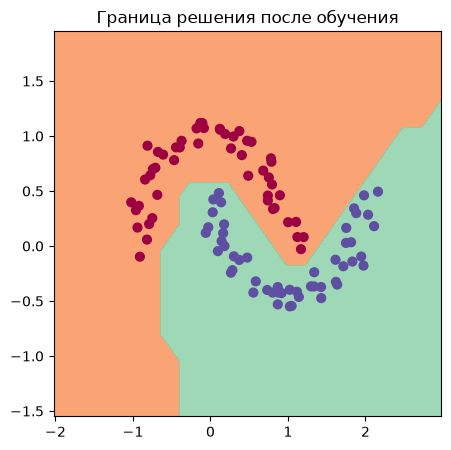

In [79]:
# Граница решения: прогоняем через сеть сетку точек по всей плоскости
# и красим каждую по знаку score. Это инференс: только forward, без обучения.
h = 0.25
x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
xx, yy = np.meshgrid(np.arange(x_min, x_max, h), np.arange(y_min, y_max, h))
Xmesh = np.c_[xx.ravel(), yy.ravel()]

inputs = [list(map(Value, xrow)) for xrow in Xmesh]
scores = list(map(model, inputs))
Z = np.array([s.data > 0 for s in scores]).reshape(xx.shape)

plt.figure(figsize=(5, 5))
plt.contourf(xx, yy, Z, cmap=plt.cm.Spectral, alpha=0.8)
plt.scatter(X[:, 0], X[:, 1], c=y, s=40, cmap=plt.cm.Spectral)
plt.title("Граница решения после обучения")
# Прямой линией два полумесяца не разделить — сеть с ReLU рисует
# изогнутую границу. Ради этого и нужны скрытые слои (d.4.1 §2).
# Без ReLU даже 100 слоёв схлопнутся в одну линейную модель (d.4.1 §8)

### Чеклист части 8

- [ ] на первом графике два полумесяца
- [ ] за 100 шагов loss падает, accuracy доходит примерно до 100%
- [ ] на последнем графике изогнутая граница, которая разделяет классы

## Итог всего разбора

1. **Производная** — скорость изменения выхода, если чуть сдвинуть вход (части 1–2).
2. **`Value`** запоминает историю вычислений, то есть граф (часть 3).
3. **Backprop** идёт по этой истории от конца к началу и по правилу цепочки заполняет `.grad` (части 4 и 6).
4. **Шаг** `w -= lr * grad` обновляет веса (часть 5).
5. Из `Value` собирается **MLP**, и цикл forward → loss → zero_grad → backward → шаг его обучает (части 7–8).

В PyTorch то же самое, только с тензорами и быстро: `loss.backward()`, `optimizer.step()`, `optimizer.zero_grad()`.

Вопросы на самопроверку с ответами — в [`d.4.4`](d.4.4%20Разбор%20backword%20и%20простой%20нейросети.md).